In [18]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np
import matplotlib.pyplot as plt


In [19]:
# -----------------------------
# Load dataset
# -----------------------------
file_path = "Z:/Machine_learning Dr. Vimina/Machine Learning 2026/BCA H 2026/ML Lab Programs/Titanic-Dataset.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

In [20]:
print(data.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [21]:
# ---------------------------------------
# Display Dataset Information
# ---------------------------------------

print("\nDataset Information")
print(data.info())


Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [22]:
# ---------------------------------------
# Drop Unnecessary Columns
# ---------------------------------------

data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])


In [23]:
# ---------------------------------------
# Check Missing Values
# ---------------------------------------

print("\nMissing Values")
print(data.isnull().sum())


Missing Values
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [24]:
# ---------------------------------------
# Handle Missing Values
# ---------------------------------------

# Numerical column
age_imputer = SimpleImputer(strategy="mean")
data["Age"] = age_imputer.fit_transform(data[["Age"]])

# Categorical column
embarked_imputer = SimpleImputer(strategy="most_frequent")
data["Embarked"] = embarked_imputer.fit_transform(data[["Embarked"]]).ravel()


In [25]:
# ---------------------------------------
# Check Missing Values again
# ---------------------------------------

print("\nMissing Values")
print(data.isnull().sum())


Missing Values
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [26]:
# ---------------------------------------
# Encode Categorical Variables
# ---------------------------------------

encoder = LabelEncoder()

data["Sex"] = encoder.fit_transform(data["Sex"])
data["Embarked"] = encoder.fit_transform(data["Embarked"])

print("\nAfter Encoding")
print(data.head())



After Encoding
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


In [27]:
# ---------------------------------------
# Separate Features and remove Target
# ---------------------------------------

X = data.drop("Survived", axis=1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.000000,1,0,7.2500,2
1,1,0,38.000000,1,0,71.2833,0
2,3,0,26.000000,0,0,7.9250,2
3,1,0,35.000000,1,0,53.1000,2
4,3,1,35.000000,0,0,8.0500,2
...,...,...,...,...,...,...,...
886,2,1,27.000000,0,0,13.0000,2
887,1,0,19.000000,0,0,30.0000,2
888,3,0,29.699118,1,2,23.4500,2
889,1,1,26.000000,0,0,30.0000,0


In [28]:
# ---------------------------------------
# Feature Scaling
# ---------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [29]:
# 6. Create Agglomerative Clustering model
# ==========================================================

model = AgglomerativeClustering(n_clusters=3,linkage="ward")

In [30]:
# 7. Perform clustering
# ==========================================================

y_cluster = model.fit_predict(X_scaled)

# Add cluster labels to the original dataset

data["Cluster"] = y_cluster

In [31]:
# ==========================================================
# 9. Display number of passengers in each cluster
# ==========================================================

print("\nNumber of Passengers in Each Cluster:")

for cluster in range(3):

    count = np.sum(y_cluster == cluster)

    print("Cluster", cluster,":", count, "passengers")



Number of Passengers in Each Cluster:
Cluster 0 : 261 passengers
Cluster 1 : 175 passengers
Cluster 2 : 455 passengers


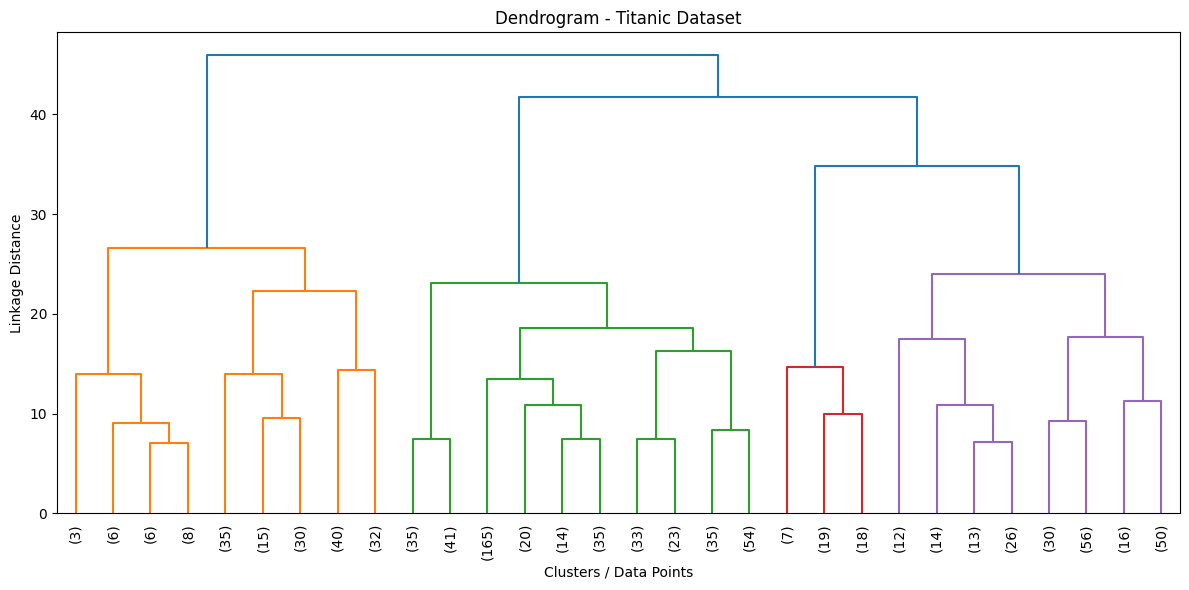

In [32]:
# ==========================================================
# 12. Generate the linkage matrix for dendrogram
# ==========================================================

Z = linkage(X_scaled,method="ward")

# ==========================================================
# 13. Plot the dendrogram
# ==========================================================

plt.figure(figsize=(12, 6))

dendrogram(Z,truncate_mode="lastp",p=30,leaf_rotation=90,leaf_font_size=10)
#truncate_mode="lastp": Displays only the last p merged clusters and their relevant descendants
#p=30: Displays at most 30 leaf nodes in the truncated dendrogram

plt.title("Dendrogram - Titanic Dataset")

plt.xlabel("Clusters / Data Points")

plt.ylabel("Linkage Distance")

plt.tight_layout()

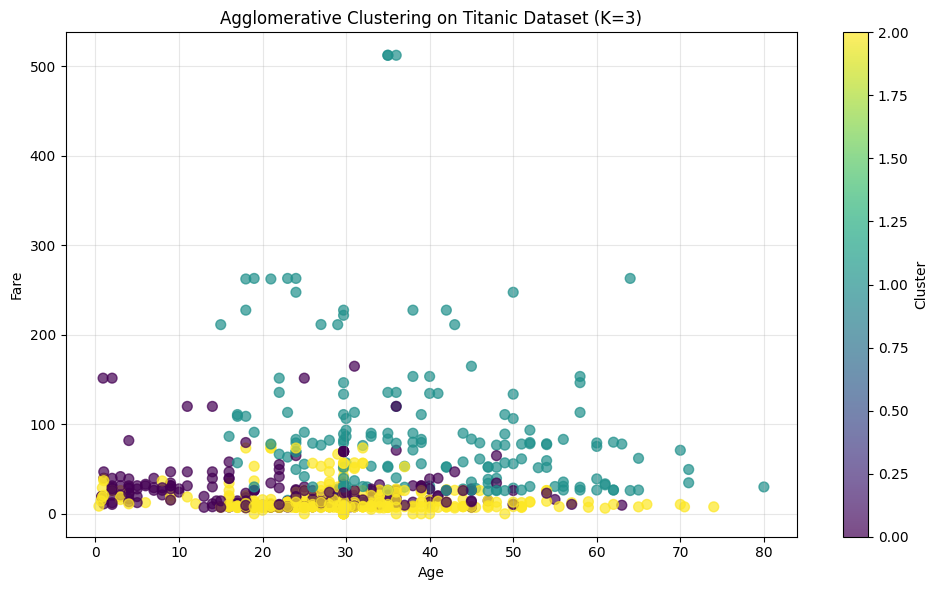

In [33]:
# 11. Visualize the clusters
# ==========================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    X["Age"],
    X["Fare"],
    c=y_cluster,
    cmap="viridis",
    s=50,
    alpha=0.7
)

plt.xlabel("Age")
plt.ylabel("Fare")

plt.title("Agglomerative Clustering on Titanic Dataset (K=3)")

plt.colorbar(label="Cluster")

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()



plt.show()


In [34]:
#Display cluster assignments
print("\nCluster assignments:")
print(y_cluster)


Cluster assignments:
[2 1 0 1 2 2 1 0 0 0 0 1 2 0 0 0 0 2 0 0 2 2 0 2 0 0 2 1 0 2 1 1 0 2 1 1 2
 2 0 0 0 0 2 0 0 2 2 0 2 0 0 2 1 0 1 2 0 2 0 0 2 1 1 0 1 2 0 2 0 2 2 0 2 2
 2 2 2 2 2 0 2 2 0 2 0 0 2 2 1 2 2 2 1 2 2 2 1 1 0 2 0 2 2 2 2 2 0 2 2 0 1
 0 2 0 0 2 2 2 1 0 2 2 1 0 1 2 2 2 0 2 2 2 0 0 2 1 0 1 2 1 0 0 0 2 2 2 2 0
 2 2 2 1 2 2 2 1 0 2 2 0 2 0 2 2 0 2 0 0 2 2 1 0 0 2 1 2 2 1 2 2 0 1 0 2 0
 2 0 1 2 2 0 2 0 2 1 1 2 2 0 0 2 0 2 2 2 0 2 2 0 1 2 0 2 2 2 1 0 2 1 2 2 2
 2 2 1 2 2 2 2 0 1 2 2 0 2 0 2 0 2 2 0 0 2 2 2 1 0 0 2 2 2 0 1 2 0 0 1 1 1
 0 2 0 1 2 0 2 0 2 1 1 2 2 0 1 0 1 0 2 0 0 2 2 2 2 2 2 2 2 2 0 1 1 1 0 2 1
 2 0 2 1 0 2 2 0 2 0 1 1 1 1 1 1 0 2 2 0 0 2 0 1 2 2 0 0 0 1 2 0 0 0 0 1 1
 2 1 2 2 1 2 1 2 1 2 2 2 0 0 0 2 2 2 2 2 2 2 2 0 0 0 0 0 1 0 2 2 2 1 0 0 1
 1 2 2 1 0 1 0 1 2 2 1 0 2 1 2 2 0 0 2 0 1 2 2 1 0 2 0 2 2 0 2 2 0 2 0 2 2
 2 2 0 2 2 1 2 2 0 0 0 2 0 2 2 2 0 2 2 0 0 2 2 2 0 0 2 1 0 0 0 1 2 0 2 2 0
 2 0 0 2 0 1 2 2 1 1 2 2 1 1 0 2 1 2 1 2 2 2 2 1 2 0 2 2 0 0 0 2 2 2 2 0 0
 2 